# Classical OFDM channel estimation

Here I wanted to see how good classical channel estimation can get for a given
modulation, pilot layout, fading model and noise level. I compare Perfect CSI, LS with
interpolation, and LMMSE (which uses the channel's mean and covariance) on exactly the
same received frames. All the algorithms are in `src/neural_ofdm` and this notebook
imports them. The baseline from notebook 01 still works as before. There are no
neural networks in this notebook.

Signal chain: bits -> Gray symbols -> pilot/data grid -> unitary IFFT -> CP -> FIR + AWGN
-> unitary FFT -> estimate H -> per-bin equalizer -> hard decisions.
One frame is one OFDM symbol. The channel stays fixed during it and is new for every frame.
All 64 bins are used, including DC. Timing is perfect and CP=16 samples.

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from neural_ofdm.benchmark import benchmark_studies, load_benchmark, run_benchmark
from neural_ofdm.benchmark_plotting import (
    plot_channel_examples,
    plot_channel_statistics,
    plot_constellation_examples,
    plot_estimation_example,
)
from neural_ofdm.channel import frequency_statistics, reference_noise_variance
from neural_ofdm.equalization import mmse_equalize
from neural_ofdm.estimation import prepare_lmmse
from neural_ofdm.modulation import constellation, demodulate
from neural_ofdm.simulation import observe_frame

root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
output = root / "results" / "classical_benchmark"
studies = benchmark_studies()
base = studies["receiver_comparison"]
print("Primary benchmark: 3000 frames/level, seed 2026, fixed independent noise")
print("Run uv run python scripts/run_classical_benchmark.py first if saved studies are absent")

Primary benchmark: 3000 frames/level, seed 2026, fixed independent noise
Run uv run python scripts/run_classical_benchmark.py first if saved studies are absent


## Modulation, energy and payload

QPSK maps (b_I,b_Q) to ((1-2*b_I)+j*(1-2*b_Q))/sqrt(2), the same as in the baseline.
16-QAM uses two Gray bits per axis: 00 -> +3, 01 -> +1, 11 -> -1, 10 -> -3,
and the complex point is divided by sqrt(10). Both constellations have Es=E[|X|^2]=1
on average, although single 16-QAM points have different energies, so I check the
energy over the whole constellation. Decisions use the sign and the boundary
abs(axis)=2/sqrt(10). A point exactly on a boundary goes to the inner level, and a
zero coordinate counts as positive.

QPSK carries 2 bits per symbol and 16-QAM carries 4. With spacing 4, 16 of the 64 bins
are pilots, so pilot_overhead=P/N=0.25 and the payload is 96 or 192 bits per frame.
The CP overhead is CP/(N+CP)=0.20. Comparing at the same Es and noise is not the same
as comparing at the same Eb/N0 or the same data rate. More pilots means less payload.

In [2]:
for order in (4, 16):
    points, labels = constellation(order)
    assert np.array_equal(demodulate(points, order).reshape(labels.shape), labels)
    print(f"Order {order}: complete-constellation Es={np.mean(np.abs(points) ** 2):.6f}")
print(f"Pilots={base.ofdm.pilot_indices.size}, overhead={base.ofdm.pilot_overhead:g}")
print(f"Payload={base.ofdm.bits_per_frame} bits/frame, CP overhead={base.ofdm.cp_overhead:g}")

Order 4: complete-constellation Es=1.000000
Order 16: complete-constellation Es=1.000000
Pilots=16, overhead=0.25
Payload=96 bits/frame, CP overhead=0.2


## Sparse delays and a power-delay profile

Each channel has L taps at delays d_l (in samples). Here I use d=(0,1,3,6) with
powers p_l=exp(-d_l/tau)/sum(exp(-d/tau)) and tau=2.5 samples. For the convolution
code it becomes a normal FIR of length max(d)+1 with zeros in between. The CP has to
cover max(d), not L-1. There are no fractional delays and no Doppler.

For Rayleigh fading each h_l is independently CN(0,p_l). So m_h=0 and C_h=diag(p),
where m_h is (L,) and C_h is (L,L). E[sum(|h_l|^2)]=1, but I don't rescale single
channels, so the overall fade still varies from frame to frame.

For Rician fading I use one global K (LOS power / scattered power):
h=sqrt(K/(K+1))*h_LOS + sqrt(1/(K+1))*g. The LOS part has energy one, sits on the first
delay and has a fixed phase of 0 radians. So m_h=sqrt(K/(K+1))*h_LOS and
C_h=diag(p)/(K+1), and the expected power on each tap is abs(m_h)^2 + p/(K+1).
A bigger K puts more power on the LOS path, which changes both how much the channel
fluctuates and how frequency selective it is. K=0 gives back the Rayleigh channel
exactly. Real models often give each path its own K; mine is simpler.

[MathWorks fading-channel background](https://www.mathworks.com/help/comm/ug/fading-channels.html)
explains LOS and scattered fading; my exact model is the one written above.

Delays: (0, 1, 3, 6)
Diffuse normalized powers: [0.48491144 0.32504586 0.14605252 0.04399017]
Tap mean shape: (4,) covariance shape: (4, 4)


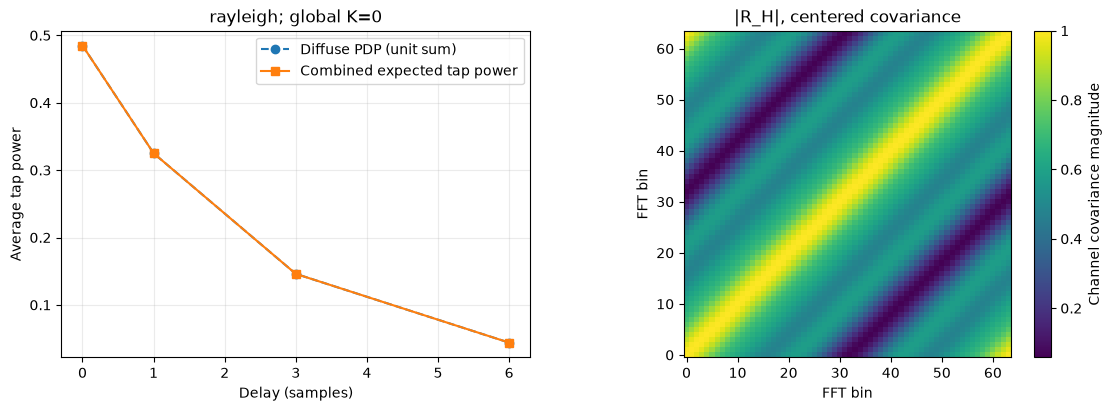

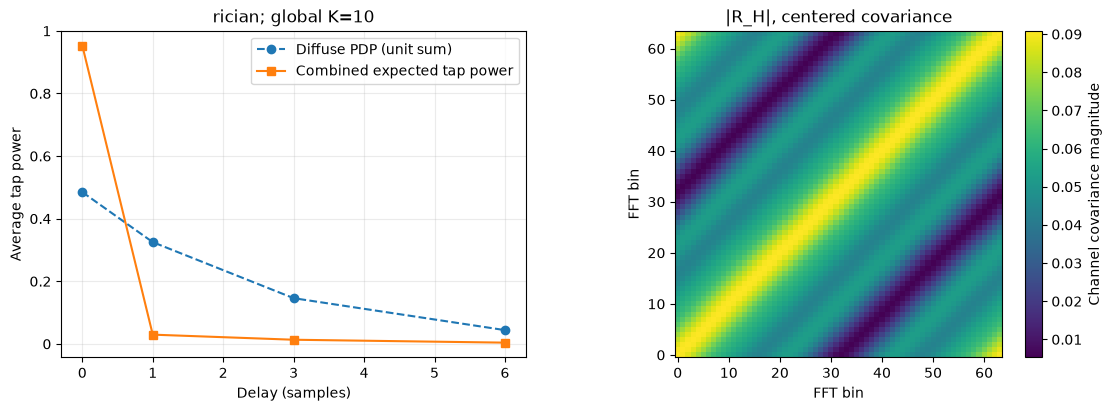

In [3]:
channel = base.ofdm.channel_prior
tap_mean, tap_covariance = channel.tap_statistics()
print("Delays:", channel.delays)
print("Diffuse normalized powers:", channel.diffuse_powers)
print("Tap mean shape:", tap_mean.shape, "covariance shape:", tap_covariance.shape)
display(plot_channel_statistics(base))
display(plot_channel_statistics(studies["rician_k10"]))
plt.close("all")

## From taps to frequency-domain mean and covariance

I define F[k,l]=exp(-j*2*pi*k*d_l/N), shape (N,L), without any 1/sqrt(N).
Then H=F*h, m_H=F*m_h and R_H=F*C_h*F^H, where ^H is the conjugate transpose.
m_H is (N,) and R_H is (N,N). R_H is the covariance around the mean,
E[(H-m_H)*(H-m_H)^H]. The raw second moment is R_H+m_H*m_H^H, which is different when
the Rician LOS part has a fixed phase. Dropping the mean would give the wrong estimator.

With the ordinary channel FFT and the unitary signal FFT, Y[k]=H[k]*X[k]+W[k] holds
when CP >= max(d). Scaling F by 1/sqrt(N) would make every gain sqrt(N) too small.
Since the average tap energy is one, E[|H[k]|^2]=1 on every bin, but neighboring bins
are correlated. That correlation is what lets the pilots say something about the data bins.

Frequency mean: (64,) covariance: (64, 64)
Minimum eigenvalue: -9.690644772866984e-15


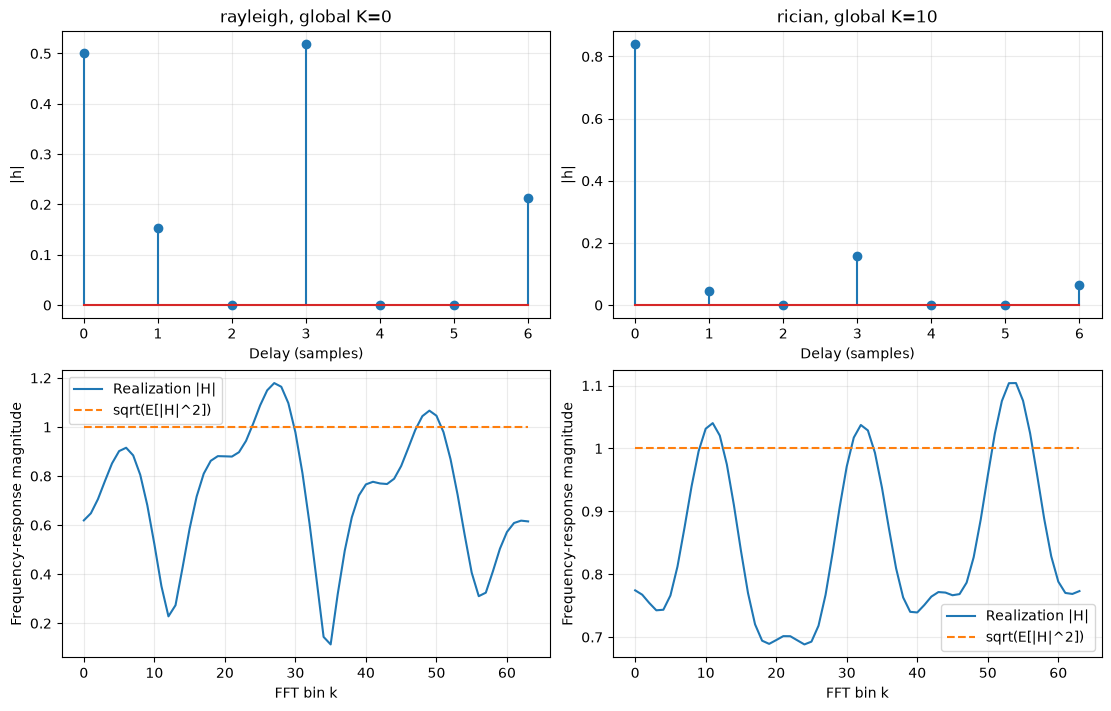

In [4]:
mean, covariance = frequency_statistics(channel, base.ofdm.fft_size)
assert covariance.shape == (64, 64)
np.testing.assert_allclose(covariance, covariance.conj().T, atol=1e-14)
assert np.linalg.eigvalsh(covariance).min() > -1e-12
np.testing.assert_allclose(np.diag(covariance), 1)
print("Frequency mean:", mean.shape, "covariance:", covariance.shape)
print("Minimum eigenvalue:", float(np.linalg.eigvalsh(covariance).min()))
display(plot_channel_examples(base))
plt.close("all")

## Two different noise definitions

The baseline default is received sample SNR: sigma^2=P_received/10^(snr_db/10).
P_received is the average clean power over the kept N+CP samples (including the CP
and the start of the channel response, not the tail). So the noise follows the
current channel and data, which hides the overall fade and doesn't match the
independent noise that LMMSE assumes.

For this benchmark I added reference_esn0_db with Es=1:
sigma^2=Es/10^(reference_esn0_db/10). This total complex noise variance is the same
for every frame at a given level, whatever the channel and data. Each real component
gets sigma^2/2. The unitary FFT keeps the same noise variance on every bin. Now a deep
fade really lowers the received SNR. Neither axis is Eb/N0, and I don't call the new
one "received SNR". The pilots have power one in the main studies, but the estimator
also handles unequal complex pilots.

In [5]:
for level in (0, 15, 30):
    print(f"Reference Es/N0={level} dB -> complex variance={reference_noise_variance(level):.8g}")
noiseless = replace(base.ofdm, reference_esn0_db=np.inf)
observation = observe_frame(noiseless, np.random.default_rng(10))
np.testing.assert_allclose(
    observation.received_grid, observation.true_channel * observation.frequency_grid, atol=1e-14
)
print("Sparse-delay useful-window relation verified with sufficient CP")

Reference Es/N0=0 dB -> complex variance=1
Reference Es/N0=15 dB -> complex variance=0.031622777
Reference Es/N0=30 dB -> complex variance=0.001
Sparse-delay useful-window relation verified with sufficient CP


## Pilot LS and LMMSE

LS first computes z_p=Y_p/X_p and then interpolates the real and imaginary parts with
straight lines, wrapping around the band edge. It needs no knowledge of the channel,
but the interpolation adds error and the pilot noise spreads to the data bins. It also
can't use the fact that the channel only has taps at certain delays.

For P pilots, Y_p=D_p*H_p+W_p, where D_p is a (P,P) diagonal matrix of the known
nonzero pilots. After dividing, z_p=H_p+v_p and R_znoise=sigma^2*diag(1/abs(X_p)^2),
shape (P,P). R_HP=R_H[:,p] is (N,P), R_PP=R_H[p,p] is (P,P) and m_P=m_H[p] is (P,).

I look for an estimate of the form H_hat=m_H+A*(z_p-m_P). Making the error
uncorrelated with the observations gives A*(R_PP+R_znoise)=R_HP, so
H_hat=m_H+R_HP*solve(R_PP+R_znoise, z_p-m_P).
The complex covariances use conjugate transposes. This gives the lowest average
squared error of any estimator of this form, and because the channel and noise are
Gaussian here it is also the best estimator overall in that sense. It is not just a
smoothed version of LS.

The code factors the observation covariance once per noise level and then applies an
(N,P) matrix to each frame. With noise it uses a Cholesky solve, never an explicit
inverse. With exactly zero noise the matrix can be singular, so I only keep the
eigenvalues above relative_tolerance*largest_eigenvalue (1e-12 by default) instead of
adding a small random jitter. The rank, cutoff and condition number are saved. For a
fixed (non-random) channel the covariance is zero, so matched LMMSE just returns the
known channel, which is basically cheating.

The true H is only used for Perfect CSI and for scoring. Matched LMMSE knows the
channel statistics and the noise variance, never the actual channel of a frame. Having
the lowest average error doesn't mean LMMSE has the lowest BER or NMSE on every frame.

The [Stanford estimation lecture](https://ee363.stanford.edu/archive/lectures/estim.pdf)
covers the background; the complex pilot equations above are my own derivation.

Operator shape: (64, 16) method: Hermitian Cholesky solve
Condition number: 246.34794038708225 jitter: 0


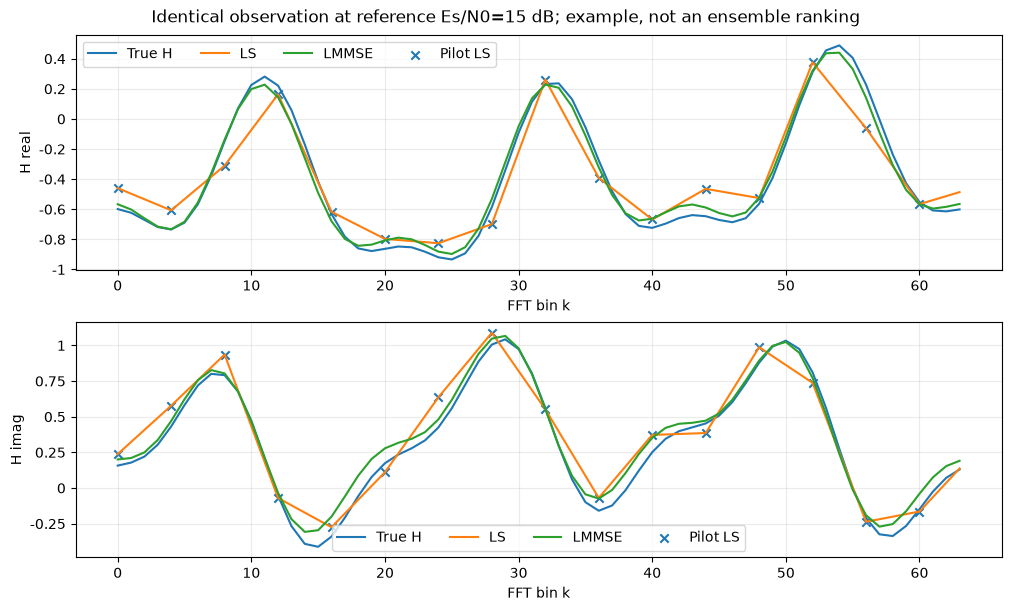

In [6]:
estimator = prepare_lmmse(
    mean, covariance, base.ofdm.pilot_indices, base.ofdm.pilot_symbols, reference_noise_variance(15)
)
print("Operator shape:", estimator.operator.shape, "method:", estimator.method)
print("Condition number:", estimator.condition_number, "jitter: 0")
display(plot_estimation_example(base, reference=15))
plt.close("all")

## A hand-checkable example and a noiseless corner case

With one pilot, m=(1+0.5j,-0.2j), R=[[2,0.3+0.4j],[0.3-0.4j,1]], X_p=2j and
sigma^2=0.8, the noise on z_p has variance 0.2. Doing it by hand gives
m + (2,0.3-0.4j)*(z-m[0])/2.2. This checks the conjugates, a pilot that isn't
power one, and the mean term.

The covariance of an N-bin channel with L taps has rank at most L, even if every bin
is a pilot. With zero noise an ordinary inverse fails. The rank-aware solve still
recovers the channel exactly whenever the pilots are enough to pin down the taps.

In [7]:
small_mean = np.array([1 + 0.5j, -0.2j])
small_covariance = np.array([[2, 0.3 + 0.4j], [0.3 - 0.4j, 1]])
small = prepare_lmmse(small_mean, small_covariance, [0], [2j], 0.8)
z = 2 - 1j
expected = small_mean + np.array([2, 0.3 - 0.4j]) * (z - small_mean[0]) / 2.2
np.testing.assert_allclose(small.estimate([2j * z, 1000j]), expected, atol=1e-14)
all_pilots = np.arange(64)
singular = prepare_lmmse(mean, covariance, all_pilots, 1, 0)
np.testing.assert_allclose(
    singular.estimate(observation.true_channel), observation.true_channel, atol=1e-13
)
print("Independent scalar example passed; noiseless covariance rank:", singular.observation_rank)

Independent scalar example passed; noiseless covariance rank: 4


## Equalization and EVM

ZF computes X_hat=Y/H_hat. Weak gains boost the noise; a clamp at magnitude 1e-10
avoids dividing by zero, counts the clamped bins and warns. It can't recover a null.
The per-bin MMSE equalizer uses W=conj(H_hat)/(abs(H_hat)^2+sigma^2/Es) and X_raw=W*Y.
This is a different thing from LMMSE channel estimation, and with an estimated H it
doesn't account for the estimation error.

Its gain is g=abs(H_hat)^2/(abs(H_hat)^2+sigma^2/Es). For a nonzero gain,
X_decision=X_raw/g=Y/H_hat, so after dividing out the gain MMSE and ZF make exactly the
same hard decisions, also for 16-QAM. The raw MMSE output can have a smaller squared
error, but using the normal 16-QAM thresholds on the shrunk output is wrong.

Payload EVM_RMS=sqrt(sum(abs(X_hat-X)^2)/sum(abs(X)^2)). I save the raw output and the
gain-corrected output separately and combine frames as sqrt(mean(frame_EVM^2)).
The main results use ZF, where the two are the same.

Effective gain: 0.24528301886792447
Raw MMSE QAM errors without correction: 16


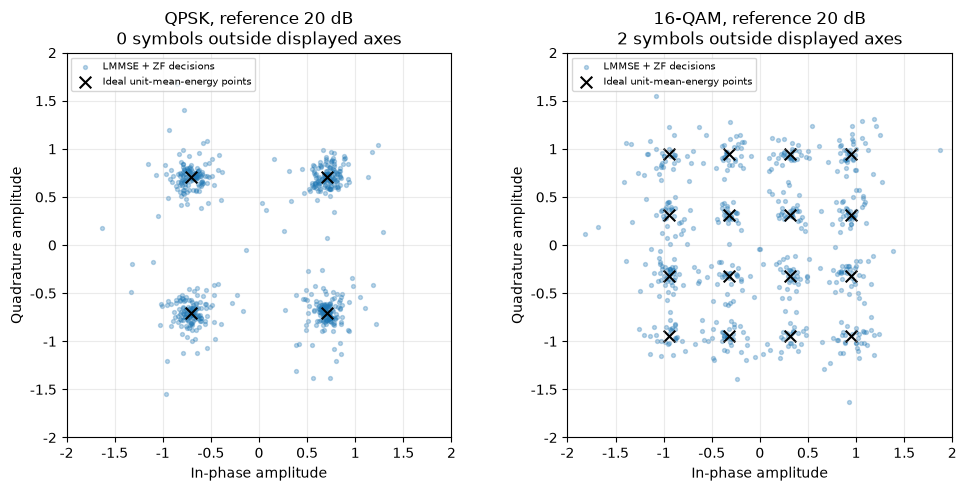

In [8]:
points, labels = constellation(16)
gains = np.full(points.size, 0.2 + 0.3j)
equalized = mmse_equalize(gains * points, gains, noise_variance=0.4)
np.testing.assert_allclose(equalized.decision_symbols, points)
assert np.array_equal(demodulate(equalized.decision_symbols, 16).reshape(labels.shape), labels)
print("Effective gain:", equalized.effective_gain[0])
print(
    "Raw MMSE QAM errors without correction:",
    np.count_nonzero(demodulate(equalized.symbols, 16) != labels.ravel()),
)
display(plot_constellation_examples(base))
plt.close("all")

## Running the experiments and error bars

`ExperimentConfig` holds the grid, channel, assumed statistics, equalizer, noise levels,
number of frames and seed. At every level three random streams restart from
SeedSequence(seed).spawn(3): payload, channel and noise, and all receivers decode the
same frames. Across pilot layouts and modulations the channels and noise samples are
the same, but the data and waveforms differ. Across K values the random scattered part
is the same but the final channels differ.

BER=sum(errors)/sum(payload bits). Mean per-frame NMSE is mean(||H_hat-H||^2/||H||^2),
in linear units. Ensemble MSE is the average squared error over all frames and bins,
and ensemble NMSE=sum(squared error)/sum(true channel energy) is yet another average.
LMMSE is optimal for ensemble MSE, not for per-frame NMSE.

Bits in the same frame share the same fade and channel estimate, so they fail
together. For the error bars I resample whole frames 1000 times, using the same frames
for every receiver. Paired BER differences are saved separately. With only a few error
frames the bars are rough, so the raw counts are worth checking. Neighboring points
reuse the same random draws, so the bars are per point, not a band for the whole curve.

If a receiver has no errors at all, a bootstrap interval would just collapse to zero,
so I leave it out. Instead I use 1-0.05^(1/frames), a 95% upper bound on the chance
that a frame has any error. A frame's BER can't be larger than that, so it also bounds
the BER. The smaller bound 1-0.05^(1/bits) only holds if bits were independent, so I
save it separately as a rough number. The triangles are bounds and are never joined
to the BER lines. I store the raw counts but not the waveforms. The run below is only
a small live demo; the conclusions come from the saved full studies.

In [9]:
demo = run_benchmark(
    replace(base, frames=120, reference_values_db=(0, 15, 30), bootstrap_replicates=200)
)
for row in demo.rows:
    print(
        f"{row['reference_esn0_db']:2g} dB {row['receiver']:7s}: errors={row['errors']:4d}/{row['total_bits']}, BER={row['ber']:.5g}, NMSE={row['nmse_mean_per_frame']:.5g}"
    )
primary = {name: load_benchmark(output / name) for name in studies}
print("Loaded independently regenerated primary CSV/JSON and frame counts")

 0 dB perfect: errors=2322/11520, BER=0.20156, NMSE=0
 0 dB ls     : errors=3197/11520, BER=0.27752, NMSE=0.87191
 0 dB lmmse  : errors=2675/11520, BER=0.2322, NMSE=0.21153
15 dB perfect: errors= 136/11520, BER=0.011806, NMSE=0
15 dB ls     : errors= 289/11520, BER=0.025087, NMSE=0.038744
15 dB lmmse  : errors= 185/11520, BER=0.016059, NMSE=0.0095927
30 dB perfect: errors=   2/11520, BER=0.00017361, NMSE=0
30 dB ls     : errors=  73/11520, BER=0.0063368, NMSE=0.012308
30 dB lmmse  : errors=   6/11520, BER=0.00052083, NMSE=0.00030877


Loaded independently regenerated primary CSV/JSON and frame counts


## A. Perfect CSI, LS and matched LMMSE

These curves use Rayleigh fading with delays (0,1,3,6), tau=2.5 samples and pilot
spacing 4. The levels go from 0 to 30 dB in 5 dB steps. Each receiver gets 288000
payload bits per level from 3000 frames. Perfect CSI shows the best possible result.
Matched LMMSE removes most of the pilot noise and interpolation error, but deep fades
still cause errors because the noise is fixed. LS keeps an interpolation error even at
high levels, while LMMSE knows where the taps are.

 0 dB perfect BER=0.210885, errors=60735/288000, NMSE=0, ensemble MSE=0
 0 dB ls      BER=0.290375, errors=83628/288000, NMSE=1.04987, ensemble MSE=0.698153
 0 dB lmmse   BER=0.245316, errors=70651/288000, NMSE=0.252368, ensemble MSE=0.177613
 5 dB perfect BER=0.107618, errors=30994/288000, NMSE=0, ensemble MSE=0
 5 dB ls      BER=0.163649, errors=47131/288000, NMSE=0.342348, ensemble MSE=0.228606
 5 dB lmmse   BER=0.128583, errors=37032/288000, NMSE=0.100723, ensemble MSE=0.0687763
10 dB perfect BER=0.0427014, errors=12298/288000, NMSE=0, ensemble MSE=0
10 dB ls      BER=0.0728889, errors=20992/288000, NMSE=0.118607, ensemble MSE=0.0801277
10 dB lmmse   BER=0.0522604, errors=15051/288000, NMSE=0.0352593, ensemble MSE=0.0237681
15 dB perfect BER=0.014441, errors=4159/288000, NMSE=0, ensemble MSE=0
15 dB ls      BER=0.0300382, errors=8651/288000, NMSE=0.0478524, ensemble MSE=0.0331775
15 dB lmmse   BER=0.0179792, errors=5178/288000, NMSE=0.0115762, ensemble MSE=0.00776682
20 dB perfect 

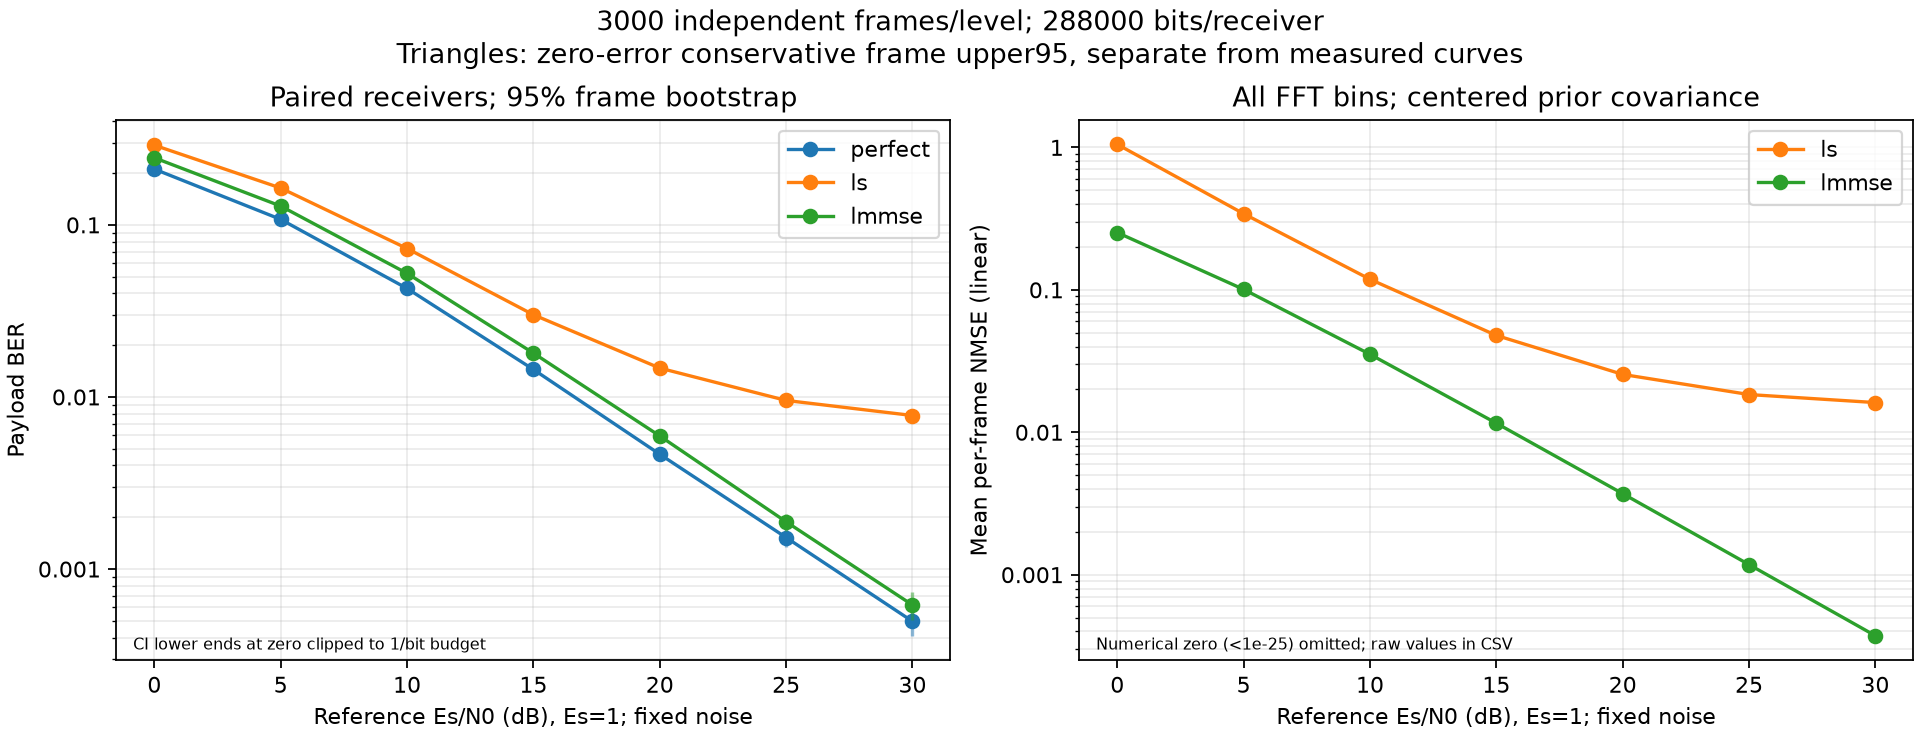

In [10]:
for row in primary["receiver_comparison"].rows:
    print(
        f"{row['reference_esn0_db']:2g} dB {row['receiver']:7s} BER={row['ber']:.6g}, errors={row['errors']}/{row['total_bits']}, NMSE={row['nmse_mean_per_frame']:.6g}, ensemble MSE={row['ensemble_mse_per_bin']:.6g}"
    )
display(Image(filename=str(output / "receiver_comparison" / "receiver_curves.png")))

## B. Pilot density versus payload

Spacing 2, 4 and 8 gives pilot overheads of 0.50, 0.25 and 0.125 and QPSK payloads of
64, 96 and 112 bits per frame. The number of frames and the noise stay the same, so the
total number of payload bits differs. More pilots means more measurements, and with
fewer pilots LS has to interpolate over longer gaps. Matched LMMSE combines the pilots
using the delay profile. The channels and noise are shared, but the data can't be,
since the grids are different. BER and NMSE alone don't show the useful data rate;
the pilot and CP overhead matter too.

pilot_spacing_2      ls    : overhead=0.5, bits=192000, BER=0.0224427, NMSE=0.0364291
pilot_spacing_2      lmmse : overhead=0.5, bits=192000, BER=0.0163802, NMSE=0.00579286
receiver_comparison  ls    : overhead=0.25, bits=288000, BER=0.0300382, NMSE=0.0478524
receiver_comparison  lmmse : overhead=0.25, bits=288000, BER=0.0179792, NMSE=0.0115762
pilot_spacing_8      ls    : overhead=0.125, bits=336000, BER=0.07175, NMSE=0.159736
pilot_spacing_8      lmmse : overhead=0.125, bits=336000, BER=0.0215714, NMSE=0.0227057


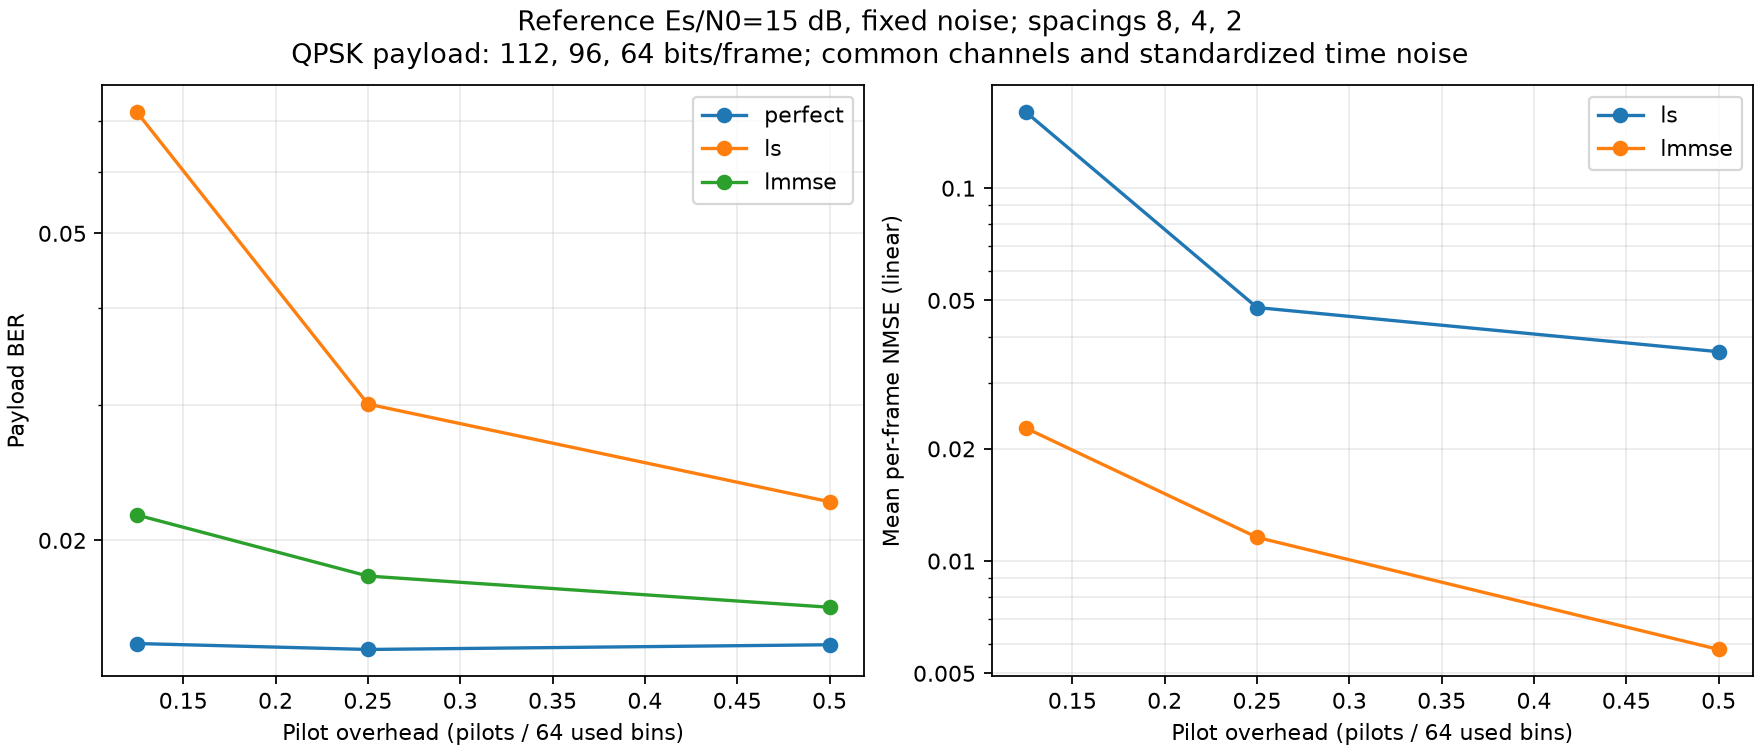

In [11]:
for name in ("pilot_spacing_2", "receiver_comparison", "pilot_spacing_8"):
    for row in primary[name].rows:
        if row["reference_esn0_db"] == 15 and row["receiver"] in ("ls", "lmmse"):
            print(
                f"{name:20s} {row['receiver']:6s}: overhead={row['pilot_overhead']:g}, bits={row['total_bits']}, BER={row['ber']:.6g}, NMSE={row['nmse_mean_per_frame']:.6g}"
            )
display(Image(filename=str(output / "figures" / "pilot_overhead.png")))

## C. QPSK versus Gray 16-QAM

Both runs use the same average symbol energy, channel profile, pilot spacing, number
of frames and noise variance. 16-QAM carries twice the bits per frame but its points
are closer together, so decisions fail more easily. The pilots, channel and pilot
noise are identical, so the channel estimates and NMSE are the same up to rounding.
The constellation plots show how noise gets boosted near fades after equalization;
points outside the plot area are counted.

receiver_comparison payload bits: 288000 BER: 0.017979166666666668 NMSE: 0.011576214586688158
modulation_16qam payload bits: 576000 BER: 0.06006770833333333 NMSE: 0.011576214586688161


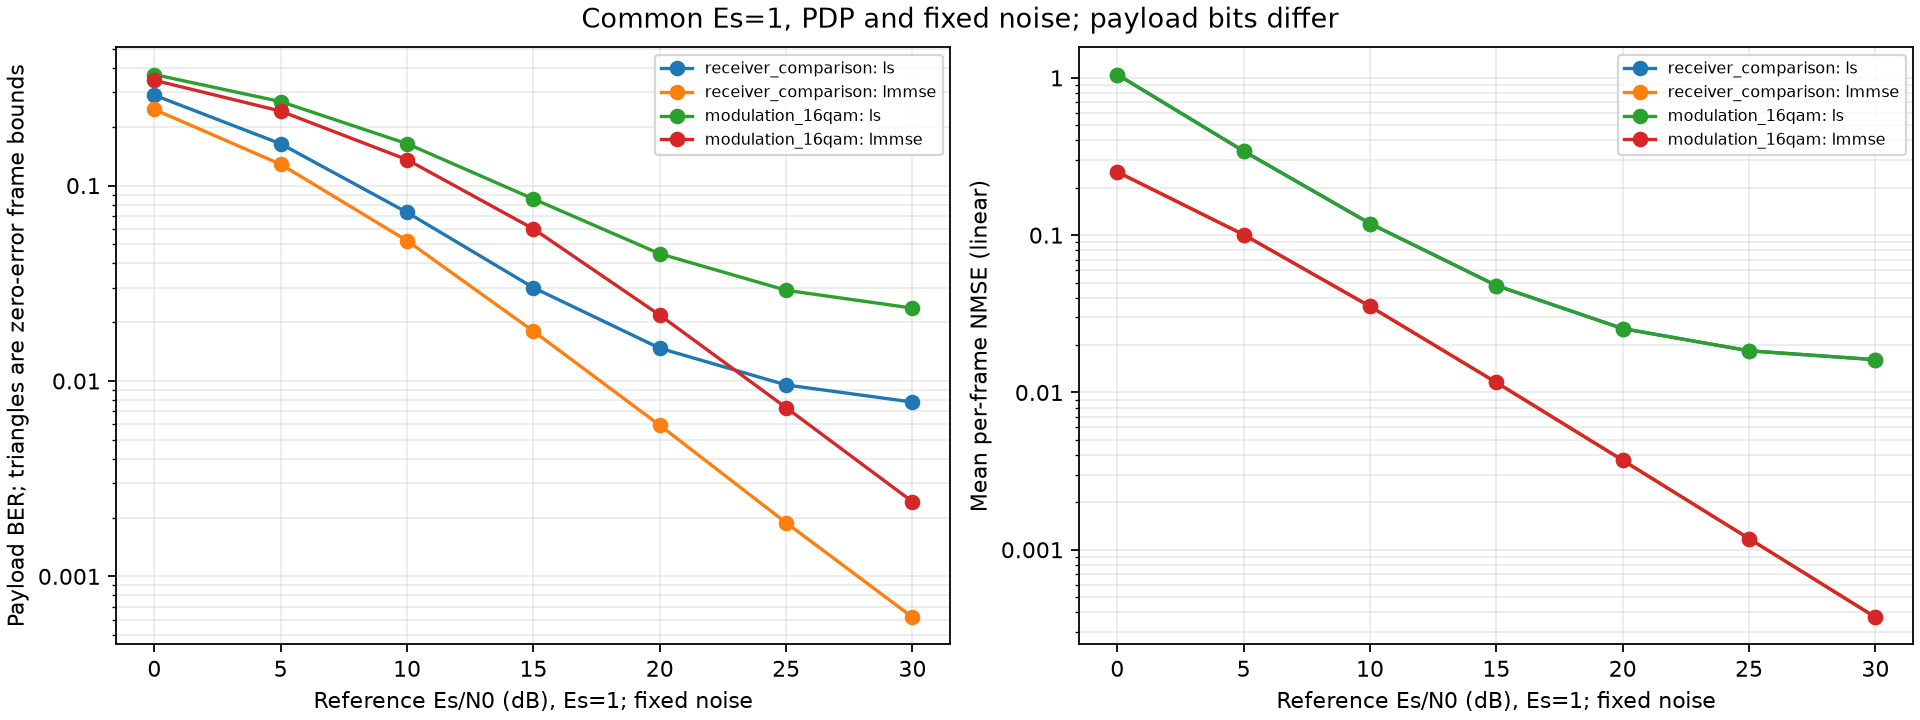

In [12]:
for name in ("receiver_comparison", "modulation_16qam"):
    row = next(
        row
        for row in primary[name].rows
        if row["receiver"] == "lmmse" and row["reference_esn0_db"] == 15
    )
    print(
        name,
        "payload bits:",
        row["total_bits"],
        "BER:",
        row["ber"],
        "NMSE:",
        row["nmse_mean_per_frame"],
    )
display(Image(filename=str(output / "figures" / "modulation_comparison.png")))

## D. Rayleigh versus Rician

K=0, 1 and 10 are linear ratios (K=1 is 0 dB, K=10 is 10 dB, K=0 is Rayleigh). The LOS
phase is fixed at zero. The average total channel energy stays one and the random part
shrinks by 1/(K+1). LMMSE keeps the fixed mean. A bigger K means fewer deep fades and
more power on the LOS path, so the better BER is a result of this particular model, not
a general rule about Rician channels. The fixed-channel study is different: there the
channel is completely known in advance, so matched LMMSE and Perfect CSI are the same.
It doesn't show anything being learned about an unknown channel.

receiver_comparison : BER=0.0179792, errors=5178/288000, NMSE=0.0115762
rician_k1           : BER=0.0143438, errors=4131/288000, NMSE=0.0113199
rician_k10          : BER=0.000201389, errors=58/288000, NMSE=0.00740216
fixed_reference     : BER=0.000194444, errors=56/288000, NMSE=3.0532e-32


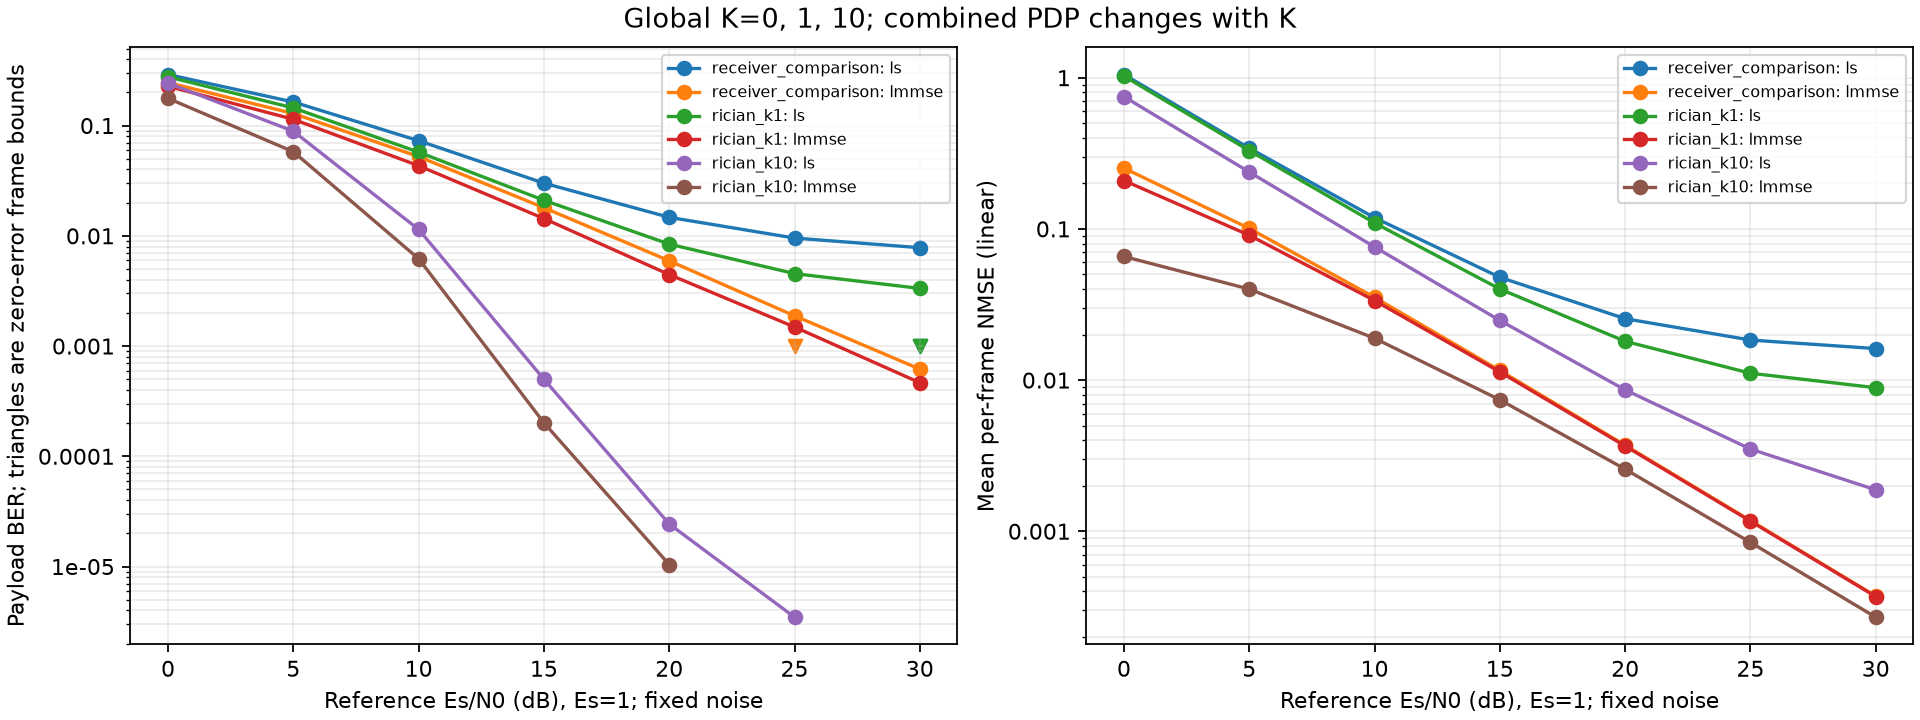

In [13]:
for name in ("receiver_comparison", "rician_k1", "rician_k10", "fixed_reference"):
    row = next(
        row
        for row in primary[name].rows
        if row["receiver"] == "lmmse" and row["reference_esn0_db"] == 15
    )
    print(
        f"{name:20s}: BER={row['ber']:.6g}, errors={row['errors']}/{row['total_bits']}, NMSE={row['nmse_mean_per_frame']:.6g}"
    )
display(Image(filename=str(output / "figures" / "fading_comparison.png")))

## E. Matched versus wrong statistics

In the first mismatch study the real channel is the normal Rayleigh one with delays
(0,1,3,6), but LMMSE assumes delays (0,1,2,3), tau=0.8 samples and twice the real noise
variance. Both versions decode exactly the same frames. The wrong delay set causes an
error floor at high levels. Because I changed the delays, profile and noise at once,
I can't say which one is responsible.

In the Rician mismatch the real channel has K=10 but LMMSE assumes K=0 (Rayleigh). That
both drops the mean and changes the covariance, so it shows the cost of using the
wrong statistics overall, not of one single parameter. Paired differences come with
frame bootstrap intervals; a positive difference means matched LMMSE had fewer errors.
I also look at MSE and NMSE, because LMMSE's optimality is about average squared error.

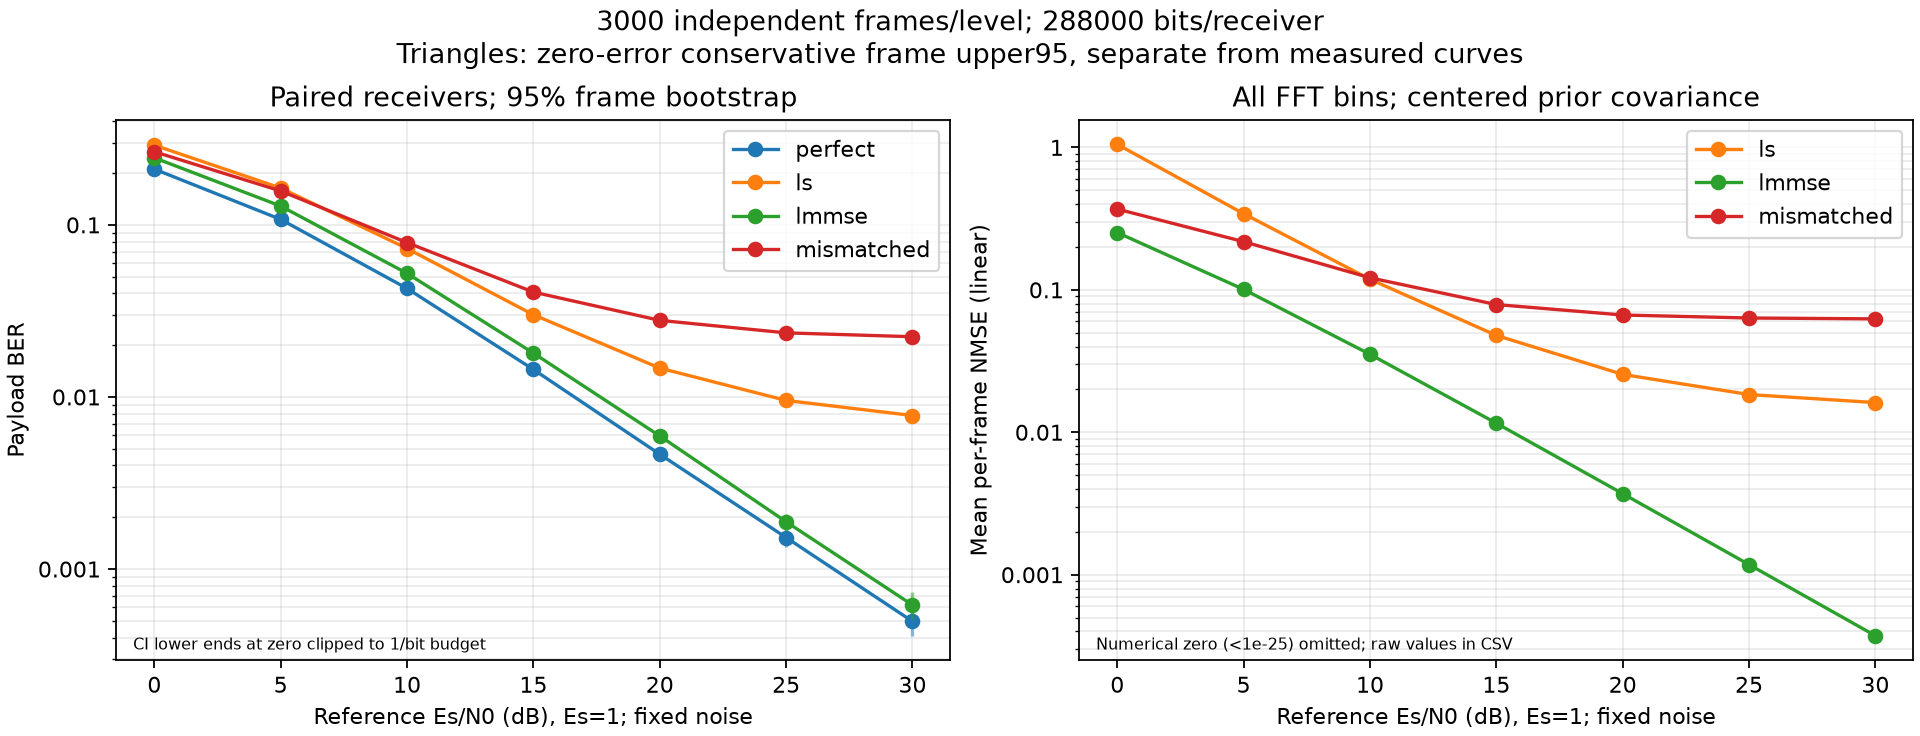

prior_mismatch {'reference_esn0_db': 15.0, 'receiver_minus_lmmse': 'mismatched', 'ber_difference': 0.022694444444444444, 'paired_bootstrap_low': 0.021482465277777776, 'paired_bootstrap_high': 0.023948697916666668, 'informative': True}
prior_mismatch {'reference_esn0_db': 30.0, 'receiver_minus_lmmse': 'mismatched', 'ber_difference': 0.021770833333333333, 'paired_bootstrap_low': 0.02038828125, 'paired_bootstrap_high': 0.023135590277777777, 'informative': True}


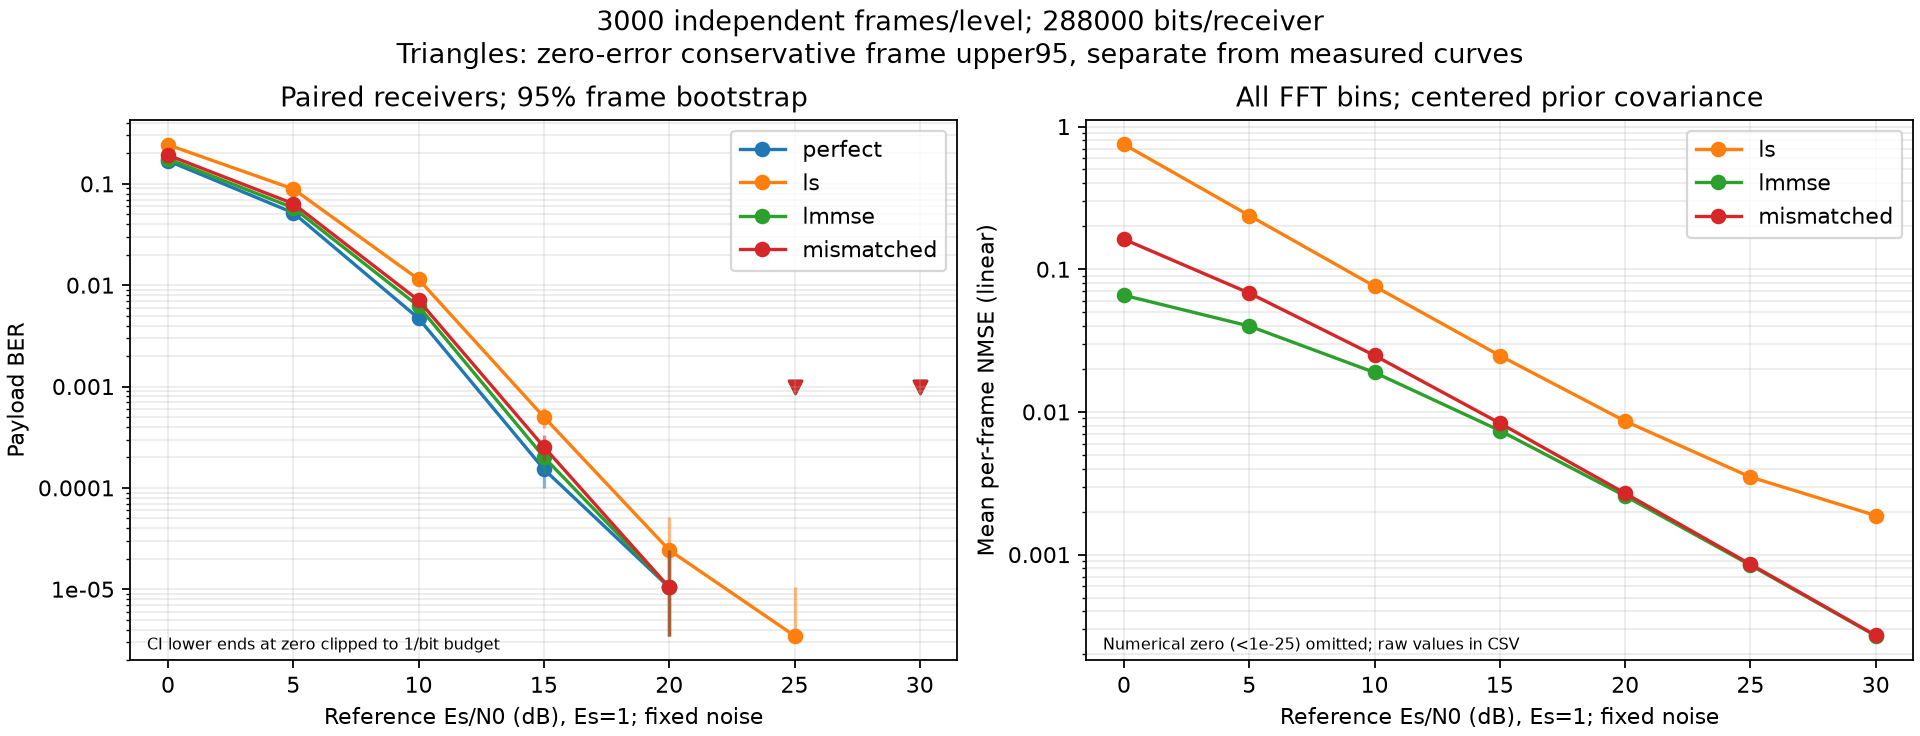

rician_mean_mismatch {'reference_esn0_db': 15.0, 'receiver_minus_lmmse': 'mismatched', 'ber_difference': 5.208333333333334e-05, 'paired_bootstrap_low': 2.4305555555555544e-05, 'paired_bootstrap_high': 7.986111111111114e-05, 'informative': True}
rician_mean_mismatch {'reference_esn0_db': 30.0, 'receiver_minus_lmmse': 'mismatched', 'ber_difference': 0.0, 'paired_bootstrap_low': 0.0, 'paired_bootstrap_high': 0.0, 'informative': False}


In [14]:
for name in ("prior_mismatch", "rician_mean_mismatch"):
    display(Image(filename=str(output / name / "receiver_curves.png")))
    for row in primary[name].comparisons:
        if row["receiver_minus_lmmse"] == "mismatched" and row["reference_esn0_db"] in (15, 30):
            print(name, row)

## Limits of these results

LMMSE uses the channel statistics I configured, so the matched results are too
optimistic if those statistics aren't known in practice. The mean, covariance, noise
independence, pilot scaling and delay positions are all assumptions built into the
receiver, and getting them wrong costs performance, as study E shows. NMSE and BER
measure different things, and per-frame NMSE gives more weight to weak channels than
ensemble MSE does.

There is no coding, synchronization error, Doppler, MIMO or real cellular framing.
3000 frames per point is enough for the main trends, but rare errors need more frames,
and zero errors never proves zero BER. The LMMSE derivation relies on Gaussian
channels and noise. The data symbols are not Gaussian, and the per-bin equalizer
doesn't account for channel-estimation error.

For the neural part I'll need separate training, validation and test frames and a fixed
rule for any input scaling. This notebook doesn't include any neural receiver.

To reproduce, from the project folder:

```
uv run python scripts/run_classical_benchmark.py --frames 3000 --seed 2026
uv run python scripts/validate_notebook.py notebooks/02_classical_channel_estimation.ipynb
```

`CLASSICAL_BENCHMARK_REPORT.md` has the measured results, the code overview and the checks.